# Fitness app users — 03 Statistical analysis

Eric Gomez · November 2026

Do engagement and effort differ between demographic groups? The answer shapes the recommendation feature.
If groups differ, recommendations could be tuned by group. If they do not, collecting and using demographics
adds privacy risk for no gain (`05`). `02` suggested no differences; this notebook tests that formally, and tests
whether any difference is small enough to ignore, which a non-significant p-value alone cannot show.

In [1]:
import sys, pathlib

ROOT = pathlib.Path.cwd()
ROOT = ROOT.parent if ROOT.name == 'notebooks' else ROOT
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.visualization.theme import PALETTE, save_fig, set_plot_style
set_plot_style()
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

In [2]:
from scipy import stats
from src.data.fitness import AGE_LABELS, GENDERS, LOCATIONS, TIERS, load_users
from src.analysis.hypothesis import (
    bootstrap_effect_ci, bootstrap_rows_ci, cramers_v, epsilon_squared, holm_adjust,
    rank_biserial, spearman_ci)
from src.visualization.presentation import save_table

users = load_users()
print(f'{len(users):,} users; distance per session available for {users["km_per_session"].notna().sum():,}')

5,000 users; distance per session available for 4,997


## DECISION 5 — hypotheses, stated before testing

Three behaviours, each tested against three attributes, plus the activity tier against the same three:

| | Outcome | Attribute | Test | Effect size | Negligible if the 90% CI lies within |
|---|---|---|---|---|---|
| H1–H3 | App sessions (frequency) | gender, location, age | Mann–Whitney, Kruskal–Wallis, Spearman | rank-biserial r, ε², ρ | ±0.1, < 0.01, ±0.1 |
| H4–H6 | km per session (distance rate) | gender, location, age | as above | as above | as above |
| H7–H9 | kcal per session (intensity) | gender, location, age | as above | as above | as above |
| H10–H12 | Activity level | gender, location, age band | chi-square independence | Cramér's V | < 0.1 |

- **Null hypothesis for each test:** no difference between groups (no association for age). Two-sided,
  α = 0.05, with the Holm correction across all twelve so that the chance of any false positive in the family
  stays at 5% (Holm, 1979).
- **Smallest effect of interest.** The bounds are Cohen's (1988) conventional "small" effects. For sessions,
  0.1 standard deviations is about four sessions a year. A difference that small would not justify
  recommending anything different to a group.
- **Equivalence verdict.** A 90% interval entirely inside the bound is a two one-sided tests (TOST) result at
  α = 0.05: the effect is shown to be negligible, not merely undetected (Lakens, 2017).

## DECISION 6 — tests and their assumptions

| Test | Used for | Why this test | Assumptions, and whether they hold |
|---|---|---|---|
| Mann–Whitney U | two genders | Rank-based; the outcomes are flat, not normal (`02`) | Independent observations: one record per user after the copies were removed (`01`). Holds |
| Kruskal–Wallis H | three locations | Rank-based extension to three groups | As above. Holds |
| Spearman ρ | age, a continuous attribute | Monotonic association without assuming linearity | As above. Holds |
| Chi-square independence | tier × attribute | Two categorical variables | Expected count of at least 5 in every cell: the smallest is about 380. Holds |

Intervals: percentile bootstrap (B = 2,000) for rank-biserial r, ε² and Cramér's V; Fisher's z for ρ. The
ε² and V intervals cannot fall below zero, so for them only the upper end is compared with the bound.

In [3]:
B = 2000
SEED = 803
NEGLIGIBLE = {'rank-biserial r': 0.1, 'epsilon squared': 0.01, 'Spearman rho': 0.1, "Cramér's V": 0.1}
OUTCOMES = {'app_sessions': 'Sessions', 'km_per_session': 'km per session', 'kcal_per_session': 'kcal per session'}

def kw_eps(groups):
    H = stats.kruskal(*groups).statistic
    return epsilon_squared(H, sum(len(g) for g in groups))

rows = []
for col, label in OUTCOMES.items():
    d = users.dropna(subset=[col])
    # gender: Mann-Whitney U, rank-biserial r
    f, m = (d.loc[d['gender'] == g, col].to_numpy() for g in GENDERS)
    p = stats.mannwhitneyu(f, m, alternative='two-sided').pvalue
    lo, hi = bootstrap_effect_ci(lambda gs: rank_biserial(gs[0], gs[1]), [f, m], B=B, seed=SEED)
    rows.append({'id': f'{label} ~ gender', 'test': 'Mann-Whitney U', 'effect': 'rank-biserial r',
                 'value': rank_biserial(f, m), 'ci90_low': lo, 'ci90_high': hi, 'p': p, 'n': len(d)})
    # location: Kruskal-Wallis, epsilon squared
    gs = [d.loc[d['location'] == l, col].to_numpy() for l in LOCATIONS]
    p = stats.kruskal(*gs).pvalue
    lo, hi = bootstrap_effect_ci(kw_eps, gs, B=B, seed=SEED)
    rows.append({'id': f'{label} ~ location', 'test': 'Kruskal-Wallis H', 'effect': 'epsilon squared',
                 'value': kw_eps(gs), 'ci90_low': lo, 'ci90_high': hi, 'p': p, 'n': len(d)})
    # age: Spearman rho, Fisher-z interval
    rho, p = stats.spearmanr(d['age'], d[col])
    lo, hi = spearman_ci(rho, len(d))
    rows.append({'id': f'{label} ~ age', 'test': 'Spearman correlation', 'effect': 'Spearman rho',
                 'value': rho, 'ci90_low': lo, 'ci90_high': hi, 'p': p, 'n': len(d)})

for attr, label in [('gender', 'gender'), ('location', 'location'), ('age_band', 'age band')]:
    table = pd.crosstab(users[attr], users['activity_level'])
    p = stats.chi2_contingency(table)[1]
    v_of = lambda d: cramers_v(pd.crosstab(d[attr], d['activity_level']))
    lo, hi = bootstrap_rows_ci(v_of, users[[attr, 'activity_level']], B=B, seed=SEED)
    rows.append({'id': f'Activity level ~ {label}', 'test': 'Chi-square independence', 'effect': "Cramér's V",
                 'value': cramers_v(table), 'ci90_low': lo, 'ci90_high': hi, 'p': p, 'n': int(table.values.sum())})

tests = pd.DataFrame(rows)
tests.insert(0, 'H', [f'H{i}' for i in range(1, len(tests) + 1)])
tests['p_holm'] = holm_adjust(tests['p'])
tests['bound'] = tests['effect'].map(NEGLIGIBLE)
two_sided = tests['effect'].isin(['rank-biserial r', 'Spearman rho'])
tests['negligible'] = np.where(two_sided,
                               (tests['ci90_low'] > -tests['bound']) & (tests['ci90_high'] < tests['bound']),
                               tests['ci90_high'] < tests['bound'])
display(tests.round(4))
_ = save_table(tests.round(5), '03_hypothesis_tests')

,H,id,test,effect,value,ci90_low,ci90_high,p,n,p_holm,bound,negligible
0,H1,Sessions ~ gender,Mann-Whitney U,rank-biserial r,0.0064,-0.0202,0.0330,0.6952,5000,1.0000,0.10,True
1,H2,Sessions ~ location,Kruskal-Wallis H,epsilon squared,0.0007,0.0001,0.0028,0.1711,5000,1.0000,0.01,True
2,H3,Sessions ~ age,Spearman correlation,Spearman rho,-0.0017,-0.0257,0.0222,0.9022,5000,1.0000,0.10,True
3,H4,km per session ~ gender,Mann-Whitney U,rank-biserial r,-0.0019,-0.0284,0.0234,0.9050,4997,1.0000,0.10,True
4,H5,km per session ~ location,Kruskal-Wallis H,epsilon squared,0.0000,0.0000,0.0013,0.9146,4997,1.0000,0.01,True
5,H6,km per session ~ age,Spearman correlation,Spearman rho,-0.0075,-0.0314,0.0165,0.5964,4997,1.0000,0.10,True
6,H7,kcal per session ~ gender,Mann-Whitney U,rank-biserial r,0.0136,-0.0130,0.0383,0.4066,5000,1.0000,0.10,True
7,H8,kcal per session ~ location,Kruskal-Wallis H,epsilon squared,0.0008,0.0001,0.0029,0.1478,5000,1.0000,0.01,True
8,H9,kcal per session ~ age,Spearman correlation,Spearman rho,-0.0063,-0.0303,0.0176,0.6538,5000,1.0000,0.10,True
9,H10,Activity level ~ gender,Chi-square independence,Cramér's V,0.0212,0.0080,0.0478,0.3239,5000,1.0000,0.10,True


saved outputs/tables/03_hypothesis_tests.csv

  H                          id                    test          effect    value  ci90_low  ci90_high       p    n  p_holm  bound  negligible
 H1           Sessions ~ gender          Mann-Whitney U rank-biserial r  0.00640  -0.02022    0.03301 0.69521 5000 1.00000   0.10        True
 H2         Sessions ~ location        Kruskal-Wallis H epsilon squared  0.00071   0.00011    0.00281 0.17109 5000 1.00000   0.01        True
 H3              Sessions ~ age    Spearman correlation    Spearman rho -0.00174  -0.02569    0.02222 0.90225 5000 1.00000   0.10        True
 H4     km per session ~ gender          Mann-Whitney U rank-biserial r -0.00195  -0.02840    0.02340 0.90504 4997 1.00000   0.10        True
 H5   km per session ~ location        Kruskal-Wallis H epsilon squared  0.00004   0.00002    0.00135 0.91459 4997 1.00000   0.01        True
 H6        km per session ~ age    Spearman correlation    Spearman rho -0.00749  -0.03145    0.01647 

### Interpretation

- **No test is significant after correction.** Eleven of the twelve raw p-values are above 0.14. The exception
  is H11, activity level by location (p = 0.019), which does not survive the Holm correction
  (p = 0.23).
- **Every effect is negligible.** All twelve 90% intervals lie inside their bounds. The largest effect anywhere
  is H11's Cramér's V of 0.034, with an upper limit of 0.055, about half the 0.1 threshold.
- **Reading H11 correctly.** A raw p of 0.019 among twelve tests is the kind of result chance produces about
  once in every five families of this size, which is what the Holm correction accounts for. Its effect size
  confirms it is too small to matter.

saved outputs/figures/03_A_effect_sizes.png


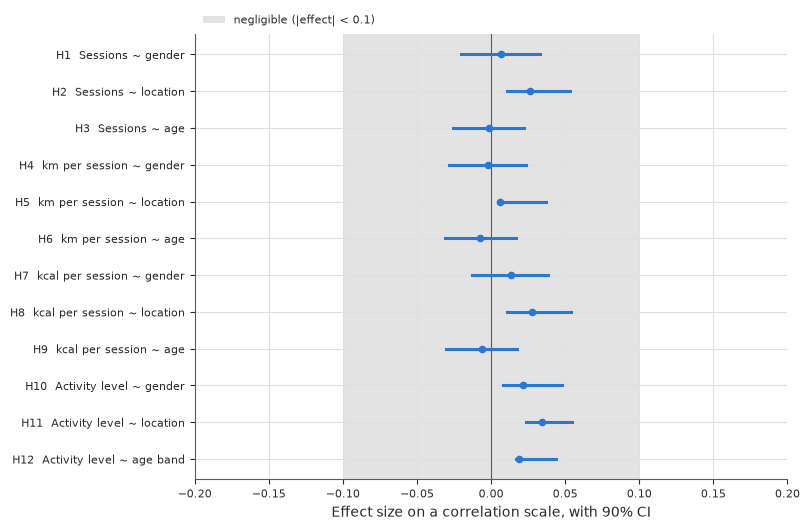

In [4]:
# One scale for all twelve: epsilon squared -> its square root, so every effect reads like a correlation
# and the conventional "small" threshold is 0.1 for all of them.
plot = tests.copy()
is_eps = plot['effect'] == 'epsilon squared'
for c in ['value', 'ci90_low', 'ci90_high']:
    plot.loc[is_eps, c] = np.sqrt(plot.loc[is_eps, c].clip(lower=0))

fig, ax = plt.subplots(figsize=(8.2, 5.4))
ax.axvspan(-0.1, 0.1, color=PALETTE['grid'], alpha=0.9, lw=0, label='negligible (|effect| < 0.1)')
ax.axvline(0, color=PALETTE['rule'], lw=0.8)
for i, r in enumerate(plot.iloc[::-1].itertuples()):
    colour = PALETTE['accent'] if r.negligible else PALETTE['alert']
    ax.plot([r.ci90_low, r.ci90_high], [i, i], color=colour, lw=2.2)
    ax.plot(r.value, i, 'o', color=colour, ms=4.5)
labels = [f'{r.H}  {r.id}' for r in plot.iloc[::-1].itertuples()]
ax.set_yticks(range(len(plot)), labels)
ax.set_xlim(-0.2, 0.2)
ax.set_xlabel('Effect size on a correlation scale, with 90% CI')
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), fontsize=8, frameon=False, borderaxespad=0.3)
fig.tight_layout()
save_fig(fig, '03_A_effect_sizes')
plt.show()

### Interpretation

- **The figure puts all twelve effects on one scale.** ε² is shown as its square root, so every effect reads like
  a correlation and the conventional "small" threshold is 0.1 for all of them.
- **Every interval sits inside the shaded band**, most of them within ±0.05. Frequency, distance per session,
  intensity and tier are the same, to within a negligible margin, for women and men, for urban, suburban and
  rural users, and across ages 18 to 59.

In [5]:
from statsmodels.stats.power import TTestIndPower, FTestAnovaPower

n_f, n_m = (users['gender'] == 'Female').sum(), (users['gender'] == 'Male').sum()
alpha_family = 0.05 / len(tests)        # the strictest Holm step, so the figures are conservative
d_gender = TTestIndPower().solve_power(nobs1=n_f, ratio=n_m / n_f, alpha=alpha_family, power=0.80)
f_loc = FTestAnovaPower().solve_power(nobs=len(users), k_groups=3, alpha=alpha_family, power=0.80)
z = stats.norm.ppf(1 - alpha_family / 2) + stats.norm.ppf(0.80)
rho_min = np.tanh(z / np.sqrt(len(users) - 3))
power = pd.DataFrame([
    {'comparison': 'two genders', 'effect': "Cohen's d", 'detectable_at_80pct_power': d_gender},
    {'comparison': 'three locations', 'effect': "Cohen's f", 'detectable_at_80pct_power': f_loc},
    {'comparison': 'age (correlation)', 'effect': 'rho', 'detectable_at_80pct_power': rho_min},
]).round(3)
print(f'alpha per test (Bonferroni bound on Holm): {alpha_family:.4f}')
display(power)
_ = save_table(power, '03_power')

alpha per test (Bonferroni bound on Holm): 0.0042


,comparison,effect,detectable_at_80pct_power
0,two genders,Cohen's d,0.105
1,three locations,Cohen's f,0.057
2,age (correlation),rho,0.052


saved outputs/tables/03_power.csv

       comparison    effect  detectable_at_80pct_power
      two genders Cohen's d                      0.105
  three locations Cohen's f                      0.057
age (correlation)       rho                      0.052


### Interpretation

- **The tests were able to find small effects.** Even at the strictest Holm step (α = 0.0042), each comparison
  had an 80% chance of detecting an effect at or near the "small" threshold: d = 0.105 between genders,
  f = 0.057 across locations and ρ = 0.052 for age.
- **So the null results are informative.** The data had enough users per group to detect a meaningful
  difference. That no difference appeared is evidence of absence, not a symptom of a small sample.

## What this does not show

- **It does not show that real users do not differ.** In New Zealand, physical-activity participation does vary
  by age, gender, ethnicity and neighbourhood deprivation. The equality here is a property of these data:
  `02` found each record consistent with independent random draws, so practically equal groups are what this dataset should show.
- **It says nothing about groups the data do not record:** ethnicity, disability, gender beyond two categories,
  and users under 18 or over 59 (`05`).
- **It is not a causal statement.** Equal averages do not mean that gender, age or location have no effect on
  any individual's behaviour.

## Implications

1. **For modelling (`04`).** Demographics should add nothing to any prediction. They stay in as candidate
   predictors so the models can show this, rather than being dropped on the strength of these tests.
2. **For the feature.** There is no evidence to tailor recommendations by gender, age or location. Using these
   attributes would add privacy risk and no measurable benefit, so the feature should not depend on them
   (data minimisation, `05`).
3. **For fairness (`05`).** Because the groups behave identically, any difference in a model's accuracy between
   groups would come from the model, not from the data, so a subgroup audit is a clean test.

## References

Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2nd ed.). Lawrence Erlbaum
Associates.

Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics,
6*(2), 65–70.

Lakens, D. (2017). Equivalence tests: A practical primer for t tests, correlations, and meta-analyses. *Social
Psychological and Personality Science, 8*(4), 355–362. https://doi.org/10.1177/1948550617697177